# Final Modeling Workflow

In this notebook, we combine the data-preparation decisions, feature engineering steps, and model-evaluation results developed during the examination of the EU 2024 FR dataset.

The workflow is designed to keep the training, validation, and final-test stages separate. All preprocessing artifacts used by the model are learned from the training data and then applied to validation and test data without refitting.

## Workflow overview

```text
2024 FR raw data
    ↓
Common cleaning and feature engineering
    ↓
Group-based train/validation split
    ↓
Fit preprocessing artifacts on the training set only
    ↓
Transform validation data
    ↓
Tune and compare candidate models
    ↓
Fit the selected model on the training data
    ↓
Transform and evaluate the 2025 FR test data
```

This structure reduces data leakage and keeps the reported validation and test metrics interpretable.

# 1. Import and Inspect the Data

Load the cleaned 2024 and 2025 FR datasets. The 2024 dataset is used for model development, while the 2025 dataset is kept separate for the final test evaluation.

In [1]:
# human-readable display settings for pandas
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

import pandas as pd

df_2024_FR_cleaned_final = pd.read_csv("../data/processed/EU/2024_FR_cleaned_final.csv")
df_2025_FR_cleaned_final = pd.read_csv("../data/processed/EU/2025_FR_cleaned_final.csv")

print("2024 FR Cleaned Final:", df_2024_FR_cleaned_final.shape)
print("2025 FR Cleaned Final:", df_2025_FR_cleaned_final.shape)

2024 FR Cleaned Final: (113868, 22)
2025 FR Cleaned Final: (88963, 23)


# Duplicate elimination
Data is grouped by the key specs columns, and measured values are replaced by weighted mean.

In [2]:
def calculate_grouped_statistics(df_2024_FR_cleaned_final):
    df = df_2024_FR_cleaned_final.copy()
    df = df[df['Ewltp (g/km)'].notna() & (df['r'] > 0)]
    df['RLFI'] = df['RLFI'].fillna('NA')

    KEY = ['Mk', 'Cn', 'Ct', 'Ft', 'Fm', 'ec (cm3)', 'ep (KW)', 'T', 'Tan', 'Va', 'Ve', 'RLFI', 'IT', 'VFN', 'm (kg)'] # group keys; known before tests
    NUM = ['Ewltp (g/km)', 'Mt', 'z (Wh/km)', 'Electric range (km)', "Fuel consumption"] # numeric columns for weighted average calculation

    # Preliminary calculation for the weighted average (rows with NaN values are also excluded from the denominator)
    for c in NUM:
        df[f'{c}__wx'] = df[c] * df['r']
        df[f'{c}__w']  = df['r'].where(df[c].notna())

    agg = {'r': 'sum', 'Ewltp (g/km)': ['std', 'min', 'max']}
    for c in NUM:
        agg[f'{c}__wx'] = 'sum'
        agg[f'{c}__w']  = 'sum'

    g = df.groupby(KEY, dropna=False).agg(agg)
    g.columns = ['_'.join(x).strip('_') for x in g.columns]
    g = g.reset_index()

    for c in NUM:
        g[c] = g[f'{c}__wx_sum'] / g[f'{c}__w_sum']
    g = g.rename(columns={'r_sum': 'r',
                        'Ewltp (g/km)_std': 'ewltp_std',
                        'Ewltp (g/km)_min': 'ewltp_min',
                        'Ewltp (g/km)_max': 'ewltp_max'})
    g = g[KEY + NUM + ['r','ewltp_std','ewltp_min','ewltp_max']]

    print(len(df), '->', len(g))
    return g

g_2024 = calculate_grouped_statistics(df_2024_FR_cleaned_final)
g_2025 = calculate_grouped_statistics(df_2025_FR_cleaned_final)

113868 -> 15957
88963 -> 14735


Checking stats:

In [3]:
def calculate_cv_statistics(g):
    g['cv'] = g['ewltp_std'] / g['Ewltp (g/km)']
    print("Median CV within the group:", g['cv'].median())
    print("Share of registrations in groups with CV > 2%:", g.loc[g['cv'] > 0.02, 'r'].sum() / g['r'].sum())
    print("Share of single-row groups:", g['ewltp_std'].isna().mean())
    return g

g_2024 = calculate_cv_statistics(g_2024)
print()
g_2025 = calculate_cv_statistics(g_2025)

Median CV within the group: 0.005060993182141505
Share of registrations in groups with CV > 2%: 0.08729790569013589
Share of single-row groups: 0.3642288650748888

Median CV within the group: 0.00528303117679484
Share of registrations in groups with CV > 2%: 0.08695885641075674
Share of single-row groups: 0.401017984390906


cleanup:

In [4]:
g_2024.drop(["ewltp_std", "cv", "ewltp_min", "ewltp_max", "Mh", "Ct"], axis=1, inplace=True, errors='ignore')
g_2025.drop(["ewltp_std", "cv", "ewltp_min", "ewltp_max", "Mh", "Ct"], axis=1, inplace=True, errors='ignore')

df_2024_FR_cleaned_final = g_2024.copy()
df_2025_FR_cleaned_final = g_2025.copy()

print("2024 FR Cleaned Final:", df_2024_FR_cleaned_final.shape)
print("2025 FR Cleaned Final:", df_2025_FR_cleaned_final.shape)

2024 FR Cleaned Final: (15957, 20)
2025 FR Cleaned Final: (14735, 20)


export data:

In [5]:
# save final cleaned data
from pathlib import Path

output_dir = Path("../data/processed/eu/splits/final/no_dupes")
output_dir.mkdir(parents=True, exist_ok=True)

df_2024_FR_cleaned_final.to_csv(output_dir / "2024_FR_cleaned_final.csv", index=False)
df_2025_FR_cleaned_final.to_csv(output_dir / "2025_FR_cleaned_final.csv", index=False)

# 2. Create the Train/Validation Split

Split the cleaned 2024 FR dataset into training and validation sets using group-based sampling.

The group columns identify related observations that must not be distributed across both subsets. This prevents information from the same group appearing in both training and validation data.

## Split requirements

- The validation set is created from the 2024 data only.
- Groups are kept intact.
- Training and validation groups must not overlap.
- The validation set is used for model comparison and feature-set evaluation.

In [6]:
# We split the 2024 FR cleaned final dataset into training and validation sets based on group columns.
from sklearn.model_selection import GroupShuffleSplit

core_physical = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft",
    "Fm"
    ]


group_columns = [
    col for col in core_physical
    if col in df_2024_FR_cleaned_final.columns
]

group_id_2024 = (
    df_2024_FR_cleaned_final
    .groupby(group_columns, dropna=False)
    .ngroup()
)

# Divide Target and Features
TARGET = "Ewltp (g/km)"
y_2024 = df_2024_FR_cleaned_final[TARGET].copy()

X_2024 = df_2024_FR_cleaned_final.drop(
    columns=[TARGET],
    errors="ignore"
).copy()

# Split
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, val_idx = next(
    gss.split(
        X_2024,
        y_2024,
        groups=group_id_2024,
    )
)

X_train = X_2024.iloc[train_idx].copy()
X_val = X_2024.iloc[val_idx].copy()

y_train = y_2024.iloc[train_idx].copy()
y_val = y_2024.iloc[val_idx].copy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)

# Control
train_groups = set(group_id_2024.iloc[train_idx])
val_groups = set(group_id_2024.iloc[val_idx])

assert train_groups.isdisjoint(val_groups)

Train: (12801, 19)
Validation: (3156, 19)


# 3. Prepare the Final Test Set

Prepare the 2025 FR dataset for the final evaluation stage.

The target column is separated from the features. The preprocessing artifacts learned during training are reused here; they are not refitted on the 2025 data.

## Final-test principles

- Do not use the 2025 target values during model selection.
- Do not fit encoders, scalers, or frequency maps on the 2025 data.
- Apply the same feature definitions used for the selected training workflow.
- Keep the final test evaluation separate from validation and hyperparameter tuning.

In [7]:
# Divide target and features for the 2025 FR cleaned final dataset
y_test = df_2025_FR_cleaned_final[TARGET].copy()

X_test = df_2025_FR_cleaned_final.drop(
    columns=[TARGET],
    errors="ignore"
).copy()

# Control
print(TARGET in df_2025_FR_cleaned_final.columns)
print(df_2025_FR_cleaned_final[TARGET].isna().sum())

True
0


### Apply Make grouping

In [8]:
# Make grouping should be learned solely from the training set
top_makes = (
    X_train["Mk"]
    .value_counts()
    .nlargest(30)
    .index
)

for frame in [X_train, X_val, X_test]:
    frame["Make_Grouped"] = frame["Mk"].where(
        frame["Mk"].isin(top_makes),
        "OTHER"
    )

# At this point:
    # New labels in validation are set to "OTHER."
    # New labels in 2025 are set to "OTHER."
    # The 2025 distribution does not affect train preprocessing.

### Apply Target encoding for Make_Grouped

In [9]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import TargetEncoder

from sklearn import set_config
set_config(enable_metadata_routing=True)

# Derive the group ID only on the train
train_groups_series = (
    X_train
    .groupby(group_columns, dropna=False)
    .ngroup()
)

train_group_ids = train_groups_series.to_numpy()

# Group-aware TargetEncoder
target_encoder_cv = GroupKFold(n_splits=5)

make_target_encoder = TargetEncoder(
    smooth="auto",
    target_type="continuous",
    cv=target_encoder_cv,
)

# Train - fit_transform (with group awareness)
X_train_make_encoded = make_target_encoder.fit_transform(
    X_train[["Make_Grouped"]],
    y_train,
    groups=train_group_ids,
)

X_train["Make_Encoded"] = X_train_make_encoded[:, 0]

# Validation - transform only
X_val_make_encoded = make_target_encoder.transform(
    X_val[["Make_Grouped"]]
)
X_val["Make_Encoded"] = X_val_make_encoded[:, 0]

# 2025 test - transform only
X_test_make_encoded = make_target_encoder.transform(
    X_test[["Make_Grouped"]]
)
X_test["Make_Encoded"] = X_test_make_encoded[:, 0]

# Drop Raw Categoricals 
drop_cols = ["Mk", "Make_Grouped"]
X_train = X_train.drop(columns=drop_cols, errors="ignore")
X_val = X_val.drop(columns=drop_cols, errors="ignore")
X_test = X_test.drop(columns=drop_cols, errors="ignore")

### Perform frequency encoding based on the training data

In [10]:
def add_frequency_feature(
    train_frame,
    other_frames,
    source_column,
    output_column,
):
    frequency_map = (
        train_frame[source_column]
        .value_counts(dropna=False)
    )

    train_frame[output_column] = (
        train_frame[source_column]
        .map(frequency_map)
        .fillna(0)
        .astype("int32")
    )

    for frame in other_frames:
        frame[output_column] = (
            frame[source_column]
            .map(frequency_map)
            .fillna(0)
            .astype("int32")
        )

    return train_frame, other_frames

frequency_columns = {
    "Cn": "Model_Frequency",
    "VFN": "VFN_Frequency",
    "Tan": "Tan_Frequency",
    "T": "T_Frequency",
    "Va": "Va_Frequency",
    "Ve": "Ve_Frequency",
    "Ct": "Ct_Frequency",
    "RLFI": "RLFI_Frequency",
}

for source_column, output_column in frequency_columns.items():
    if source_column not in X_train.columns:
        continue

    X_train, [X_val, X_test] = add_frequency_feature(
        train_frame=X_train,
        other_frames=[X_val, X_test],
        source_column=source_column,
        output_column=output_column,
    )

# Drop the original categorical columns after adding frequency features
for column in frequency_columns.keys():
    if column in X_train.columns:
        X_train.drop(columns=column, inplace=True)
        X_val.drop(columns=column, inplace=True)
        X_test.drop(columns=column, inplace=True)
    
# Important: In 2025, a category that was never seen in the training data will have a frequency of 0. This is expected behavior.

### Implement IT encoding in a shared and leakage-free manner

In [11]:
# Since no target information is used for IT, the same function can be applied to all sets
import re

IT_CODES = ["28", "29", "32", "33", "37", "38", "none"]


def extract_it_tokens(value):
    return re.findall(
        r"\b\d+\b|\bnone\b",
        str(value).lower(),
    )


def encode_it_columns(frame, it_column="IT"):
    frame = frame.copy()

    it_tokens = frame[it_column].map(
        extract_it_tokens
    )

    for code in IT_CODES:
        frame[f"IT_{code}"] = (
            it_tokens
            .map(lambda tokens: int(code in tokens))
            .astype("int8")
        )

    return frame.drop(
        columns=[it_column],
        errors="ignore"
    )

X_train = encode_it_columns(X_train)
X_val = encode_it_columns(X_val)
X_test = encode_it_columns(X_test)

### Ft, Fm One-Hot Encoding

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import pandas as pd
import re

onehot_columns = ["Ft", "Fm"]

fuel_onehot_pipeline = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("fuel_onehot", fuel_onehot_pipeline, onehot_columns),
    ],
    remainder="passthrough",
    sparse_threshold=0,
)

# Fit and transform
X_train_encoded_array = preprocessor.fit_transform(X_train)
X_val_encoded_array   = preprocessor.transform(X_val)
X_test_encoded_array  = preprocessor.transform(X_test)

# Get all column names and remove prefixes
raw_columns = preprocessor.get_feature_names_out()

def clean_column_name(name: str) -> str:
    """Remove 'fuel_onehot__' and 'remainder__' prefixes"""
    return re.sub(r"^(fuel_onehot|remainder)__", "", name)

all_columns = [clean_column_name(col) for col in raw_columns]

# Convert to DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded_array,
    columns=all_columns,
    index=X_train.index,
)

X_val_encoded = pd.DataFrame(
    X_val_encoded_array,
    columns=all_columns,
    index=X_val.index,
)

X_test_encoded = pd.DataFrame(
    X_test_encoded_array,
    columns=all_columns,
    index=X_test.index,
)

In [13]:
print(X_train_encoded.columns.to_list())
print(X_val_encoded.columns.to_list())
print(X_test_encoded.columns.to_list())

['Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
['Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
['Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'r', 'Make_Encoded', '

### Group-Aware Split Validation:

In [14]:
# unseen configuration identifiers
configuration_features = [
    "m (kg)", "ec (cm3)", "ep (KW)", 'Ft_diesel', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P']

configuration_features = [
    col for col in configuration_features
    if col in X_train_encoded.columns
]

def make_configuration_id(frame, columns):
    return (
        frame[columns]
        .astype(str)
        .fillna("<NA>")
        .agg("|".join, axis=1)
    )

train_config_id = make_configuration_id(
    X_train_encoded,
    configuration_features,
)

val_config_id = make_configuration_id(
    X_val_encoded,
    configuration_features,
)

test_config_id = make_configuration_id(
    X_test_encoded,
    configuration_features,
)

train_configuration_set = set(train_config_id)

val_overlap = val_config_id.isin(train_configuration_set)
test_overlap = test_config_id.isin(train_configuration_set)

print(
    "Validation rows with an exact train configuration:",
    f"{val_overlap.sum():,} / {len(val_overlap):,}",
    f"({val_overlap.mean() * 100:.2f}%)",
)

print(
    "2025 rows with an exact train configuration:",
    f"{test_overlap.sum():,} / {len(test_overlap):,}",
    f"({test_overlap.mean() * 100:.2f}%)",
)

print(
    "\nUnique train configurations:",
    f"{train_config_id.nunique():,}",
)

print(
    "Unique validation configurations:",
    f"{val_config_id.nunique():,}",
)

print(
    "Unique 2025 configurations:",
    f"{test_config_id.nunique():,}",
)

Validation rows with an exact train configuration: 0 / 3,156 (0.00%)
2025 rows with an exact train configuration: 9,961 / 14,735 (67.60%)

Unique train configurations: 2,299
Unique validation configurations: 575
Unique 2025 configurations: 2,542


### Group-Aware Validation Split

To prevent identical core vehicle configurations from appearing in both training and validation data, the 2024 dataset was split using a group-aware strategy.

A core technical configuration was defined by the following features:

- Vehicle mass: `m (kg)`
- Engine capacity: `ec (cm3)`
- Engine power: `ep (KW)`
- Fuel type: `Ft`
- Fuel mode: `Fm`

The resulting 2024 split contained:

- 2,514 unique core configurations in the training data
- 569 unique core configurations in the validation data
- 0 exact core-configuration overlaps between training and validation records

Therefore, the validation set evaluates the model on technical vehicle configurations that were not observed during training.

The 2025 temporal test set contained 87,909 records. Of these, 60,276 records (68.57%) had a core technical configuration already present in the 2024 training data, while 27,633 records (31.43%) represented previously unseen core configurations. Final 2025 performance should therefore be reported for all records, seen configurations, and unseen configurations separately.

### Scaling

In [15]:
from sklearn.preprocessing import StandardScaler

# Prepare Scaled Data (FOR LINEAR MODELS ONLY) ---
# Scale only the continuous numeric columns
numeric_cols = [
    "ec (cm3)",
    "ep (KW)",
    "m (kg)",
    "Mt",
    "z (Wh/km)",
    "Electric range (km)",
    "Fuel consumption",
    "Model_Frequency",
    "Make_Encoded",
    "VFN_Frequency",
    "Tan_Frequency",
    "T_Frequency",
    "Va_Frequency",
    "Ve_Frequency",
    "Ct_Frequency",
    "RLFI_Frequency",
]

# Retrieve only the existing columns (safety)
numeric_cols = [
    col for col in numeric_cols
    if col in X_train_encoded.columns
]

scaler = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_cols),
    ],
    remainder="passthrough",
)

# Fit and transform the training data
X_train_encoded_scaled_array = scaler.fit_transform(X_train_encoded)

# only transform the validation and test data
X_val_encoded_scaled_array = scaler.transform(X_val_encoded)
X_test_encoded_scaled_array = scaler.transform(X_test_encoded)

# Keep column names
scaled_cols = numeric_cols
remainder_cols = [
    col for col in X_train_encoded.columns
    if col not in numeric_cols
]
all_columns = scaled_cols + remainder_cols

# Convert to DataFrame
X_train_encoded_scaled = pd.DataFrame(
    X_train_encoded_scaled_array,
    columns=all_columns,
    index=X_train_encoded.index,
)

X_val_encoded_scaled = pd.DataFrame(
    X_val_encoded_scaled_array,
    columns=all_columns,
    index=X_val_encoded.index,
)

X_test_encoded_scaled = pd.DataFrame(
    X_test_encoded_scaled_array,
    columns=all_columns,
    index=X_test_encoded.index,
)

# -----------------------------------------------------
# 5) Checks
# -----------------------------------------------------

print("X_train_encoded_scaled shape:", X_train_encoded_scaled.shape)
print("X_train_encoded_scaled columns list:", X_train_encoded_scaled.columns.tolist())
print("X_train_encoded_scaled empty data:", X_train_encoded_scaled.isna().sum().sum())
print("X_train_encoded_scaled data types:", X_train_encoded_scaled.dtypes.value_counts())

# Print verification of scaled data (mean ≈ 0, std ≈ 1)
print("X_train_encoded_scaled scaled columns mean:\n", X_train_encoded_scaled[numeric_cols].mean().round(4))
print("\nX_train_encoded_scaled scaled columns std:\n", X_train_encoded_scaled[numeric_cols].std().round(4))
print("\n*********\n")

print("X_val_encoded_scaled shape:", X_val_encoded_scaled.shape)
print("X_val_encoded_scaled columns list:", X_val_encoded_scaled.columns.tolist())
print("X_val_encoded_scaled empty data:", X_val_encoded_scaled.isna().sum().sum())
print("X_val_encoded_scaled data types:", X_val_encoded_scaled.dtypes.value_counts())
print("\n*********\n")

print("X_test_encoded_scaled shape:", X_test_encoded_scaled.shape)
print("X_test_encoded_scaled columns list:", X_test_encoded_scaled.columns.tolist())
print("X_test_encoded_scaled empty data:", X_test_encoded_scaled.isna().sum().sum())
print("X_test_encoded_scaled data types:", X_test_encoded_scaled.dtypes.value_counts())

# Check column alignment
assert list(X_train_encoded_scaled.columns) == list(X_val_encoded_scaled.columns)
assert list(X_train_encoded_scaled.columns) == list(X_test_encoded_scaled.columns)

X_train_encoded_scaled shape: (12801, 30)
X_train_encoded_scaled columns list: ['ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
X_train_encoded_scaled empty data: 0
X_train_encoded_scaled data types: float64    30
Name: count, dtype: int64
X_train_encoded_scaled scaled columns mean:
 ec (cm3)               0.0000
ep (KW)               -0.0000
m (kg)                 0.0000
Mt                    -0.0000
z (Wh/km)             -0.0000
Electric range (km)    0.0000
Fuel consumption       0.0000
Model_Frequency        0.0000
Make_Encoded          -0.0000
VFN_Frequency         -0.0000
Tan_Frequency         -0.0000
T_Frequency           -0.0000
Va_Frequen

### Export Encoded and Scaled data

In [16]:
from pathlib import Path
import joblib

split_dir = Path("../data/processed/eu/splits/final")
artefacts_dir = Path("../artefacts/final")

# If the folder doesn't exist, create it; if it does exist, don't return an error
split_dir.mkdir(parents=True, exist_ok=True)
artefacts_dir.mkdir(parents=True, exist_ok=True)

# Save split metadata for reproducibility
split_metadata = {
    "core_configuration_columns": [
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm",
    ],
    "random_state": 42,
    "train_indices": train_idx,
    "validation_indices": val_idx,
}

joblib.dump(
    split_metadata,
    artefacts_dir / "core_physical_group_split_2024.joblib",
)

# save encoded split data
X_train_encoded.to_parquet(split_dir / "X_train_encoded_final.parquet", index=True)
X_val_encoded.to_parquet(split_dir / "X_val_encoded_final.parquet", index=True)
X_test_encoded.to_parquet(split_dir / "X_test_encoded_final.parquet", index=True)

# save encoded and scaled split data
X_train_encoded_scaled.to_parquet(split_dir / "X_train_encoded_scaled_final.parquet", index=True)
X_val_encoded_scaled.to_parquet(split_dir / "X_val_encoded_scaled_final.parquet", index=True)
X_test_encoded_scaled.to_parquet(split_dir / "X_test_encoded_scaled_final.parquet", index=True)

y_train.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train.parquet", index=True)
y_val.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_val.parquet", index=True)
y_test.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test.parquet", index=True)


# control
print("******")
print("X_train_encoded saved:", (split_dir / "X_train_encoded_final.parquet").exists())
print("X_val_encoded saved:", (split_dir / "X_val_encoded_final.parquet").exists())
print("X_test_encoded saved:", (split_dir / "X_test_encoded_final.parquet").exists())
print("******")
print("X_train_encoded_scaled saved:", (split_dir / "X_train_encoded_scaled_final.parquet").exists())
print("X_val_encoded_scaled saved:", (split_dir / "X_val_encoded_scaled_final.parquet").exists())
print("X_test_encoded_scaled saved:", (split_dir / "X_test_encoded_scaled_final.parquet").exists())
print("******")
print("y_train saved:", (split_dir / "y_train.parquet").exists())
print("y_val saved:", (split_dir / "y_val.parquet").exists())
print("y_test saved:", (split_dir / "y_test.parquet").exists())


******
X_train_encoded saved: True
X_val_encoded saved: True
X_test_encoded saved: True
******
X_train_encoded_scaled saved: True
X_val_encoded_scaled saved: True
X_test_encoded_scaled saved: True
******
y_train saved: True
y_val saved: True
y_test saved: True


# 4. Compare Feature Sets

Evaluate the leading tree-based model using the candidate feature sets.

## Feature-set definitions

- **Strict design-stage:** Features expected to be available before the additional specification information is known.
- **Extended specification:** The strict feature set plus electric-range and eco-innovation technology indicators.

The comparison is performed on the same validation split so that the effect of the additional features can be assessed fairly.

| Colon            | Decision               | Reasoning                                                                                             |
| ---------------- | ---------------------- | ----------------------------------------------------------------------------------------------------- |
| Fuel consumption | Drop                  | WLTP CO2 is nearly deterministic and comes from the same test context                                 |
| Erwltp (g/km)    | Drop                  | Post-certification eco-innovation CO2 credit.                                                         |
| Mt               | Drop                  | WLTP test mass; determined in the context of testing and type approval                                |
| z (Wh/km)        | Drop                  | WLTP electricity consumption; very close to the test results                                          |
| Make_Encoded     | Drop from the first base model | Target encoding; Since it carries the brand's CO2 average, it is an unnecessary target-derived signal in the physical model |
| Model_Frequency  | Drop                  | A proxy for the model's popularity; not a physical CO2 characteristic                                 |
| VFN_Frequency    | Drop                  | ID proxy derived from the vehicle family identifier                                                   |
| Tan_Frequency    | Drop                  | Type-approval identifier proxy                                                                        |
| T_Frequency      | Drop                  | Vehicle type identifier proxy                                                                         |
| Va_Frequency     | Drop                  | Variant identifier proxy                                                                              |
| Ve_Frequency     | Drop                  | Version identifier proxy                                                                              |
| Ct_Frequency     | Drop                  | Type-approval category frequency; low practical contribution to physical prediction                   |
| RLFI_Frequency   | Drop                  | Road-load-family ID proxy                                                                             |

### Those that will remain in the core leakage-free feature set:
| Feature             | Decision             | Reasoning                                                                                      |
| ------------------- | -------------------- | ---------------------------------------------------------------------------------------------- |
| m (kg)              | Keep                 | The vehicle's mass; can be determined during the design phase                                  |
| ec (cm3)            | Keep                 | Engine capacity                                                                                |
| ep (KW)             | Keep                 | Engine power                                                                                   |
| Ft_*                | Keep                 | Fuel type                                                                                      |
| Fm_*                | Keep                 | Fuel mode / powertrain yapısı                                                                  |
| Electric range (km) | Try on both models   | It is powerful for a PHEV; however, it depends on the prediction time scenario                 |
| IT_*                | Try on both models   | Can be considered a design technology; it can also be viewed as a field of regulatory approval |

## 4.1 Interpret the Feature-Set Results

The extended specification feature set provides additional predictive information compared with the strict design-stage feature set.

The extended model is therefore used as the primary feature set when electric range and eco-innovation technology indicators are available at prediction time.

The strict design-stage model remains relevant for earlier predictions, where those additional specification variables are not yet available.

| Model use case | Feature set | Prediction context |
|---|---|---|
| Early-stage prediction | Strict design-stage | Only information available at the earlier design stage is used. |
| Specification-based prediction | Extended specification | Electric range and eco-innovation indicators are available. |

### Model A: Strict design-stage model
It uses the key characteristics of a vehicle that are known before its official WLTP test results are available:

```python
STRICT_DESIGN_FEATURES = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Ft_petrol/electric",
    "Ft_diesel/electric",
    "Fm_H",
    "Fm_M",
    "Fm_P",
]
```
This model:
- has the lowest risk of leakage.
- measures the ability to generalize realistically to new technical configurations.

### Model B — Extended specification model
It includes additional information that we assume is included in the design/product specifications:

```python
EXTENDED_SPEC_FEATURES = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Ft_petrol/electric",
    "Ft_diesel/electric",
    "Fm_H",
    "Fm_M",
    "Fm_P",
    "Electric range (km)",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]
```
***Electric range and eco-innovation technology indicators are assumed to be available as design specifications before the final WLTP CO2 value is predicted.

Let's get our first impression using LazyPredict:

# 5. Evaluate Candidate Regressors

Evaluate the available regression models on the same encoded and scaled training/validation data.

The purpose of this stage is to identify promising model families before hyperparameter tuning. The comparison uses the same validation split and the same evaluation metrics for every candidate.

## Evaluation metrics

- **MAE:** Mean Absolute Error; lower values are better.
- **RMSE:** Root Mean Squared Error; lower values are better and larger errors receive more weight.
- **R²:** Coefficient of determination; higher values are better.
- **Adjusted R²:** R² adjusted for the number of predictors.
- **Training time:** Useful for understanding the cost of each candidate model.

In [17]:
from lazypredict.Supervised import REGRESSORS
from lazypredict import LazyRegressor

# Exclude some troublesome regressors
safe_regressors = [
    cls
    for name, cls in REGRESSORS
    if ((name != "GaussianProcessRegressor") and (name != "KernelRidge") and (name != "NuSVR"))
]

print("Total number of available regressors:", len(REGRESSORS))
print("\nList of safe regressors:\n", [cls.__name__ for cls in safe_regressors])


# Wrap each regressor so we can see which model is currently running
def make_verbose_regressor(cls):
    class VerboseRegressor(cls):
        def fit(self, X, y, *args, **kwargs):
            print(f"\n>>> STARTING: {cls.__name__}", flush=True)
            result = super().fit(X, y, *args, **kwargs)
            print(f">>> FINISHED: {cls.__name__}", flush=True)
            return result

    VerboseRegressor.__name__ = cls.__name__
    VerboseRegressor.__qualname__ = cls.__qualname__

    return VerboseRegressor


verbose_regressors = [
    make_verbose_regressor(cls)
    for cls in safe_regressors
]


reg = LazyRegressor(
    verbose=1,
    ignore_warnings=True,
    regressors=verbose_regressors,
)

models, predictions = reg.fit(
    X_train_encoded_scaled,
    X_val_encoded_scaled,
    y_train,
    y_val,
)

models

Total number of available regressors: 41

List of safe regressors:
 ['AdaBoostRegressor', 'BaggingRegressor', 'BayesianRidge', 'DecisionTreeRegressor', 'DummyRegressor', 'ElasticNet', 'ElasticNetCV', 'ExtraTreeRegressor', 'ExtraTreesRegressor', 'GammaRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor', 'HuberRegressor', 'KNeighborsRegressor', 'Lars', 'LarsCV', 'Lasso', 'LassoCV', 'LassoLars', 'LassoLarsCV', 'LassoLarsIC', 'LinearRegression', 'LinearSVR', 'MLPRegressor', 'OrthogonalMatchingPursuit', 'OrthogonalMatchingPursuitCV', 'PassiveAggressiveRegressor', 'PoissonRegressor', 'QuantileRegressor', 'RANSACRegressor', 'RandomForestRegressor', 'Ridge', 'RidgeCV', 'SGDRegressor', 'SVR', 'TransformedTargetRegressor', 'TweedieRegressor', 'LGBMRegressor']


  0%|          | 0/38 [00:00<?, ?it/s]


>>> STARTING: AdaBoostRegressor
>>> FINISHED: AdaBoostRegressor

>>> STARTING: BaggingRegressor
>>> FINISHED: BaggingRegressor

>>> STARTING: BayesianRidge
>>> FINISHED: BayesianRidge

>>> STARTING: DecisionTreeRegressor
>>> FINISHED: DecisionTreeRegressor

>>> STARTING: DummyRegressor
>>> FINISHED: DummyRegressor

>>> STARTING: ElasticNet
>>> FINISHED: ElasticNet

>>> STARTING: ElasticNetCV

>>> STARTING: ExtraTreeRegressor
>>> FINISHED: ExtraTreeRegressor

>>> STARTING: ExtraTreesRegressor
>>> FINISHED: ExtraTreesRegressor

>>> STARTING: GammaRegressor
>>> FINISHED: GammaRegressor

>>> STARTING: GradientBoostingRegressor
>>> FINISHED: GradientBoostingRegressor

>>> STARTING: HistGradientBoostingRegressor
>>> FINISHED: HistGradientBoostingRegressor

>>> STARTING: HuberRegressor
>>> FINISHED: HuberRegressor

>>> STARTING: KNeighborsRegressor
>>> FINISHED: KNeighborsRegressor

>>> STARTING: Lars
>>> FINISHED: Lars

>>> STARTING: LarsCV
>>> FINISHED: LarsCV

>>> STARTING: Lasso
>>> FINI

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
RandomForestRegressor,0.9995,0.9995,1.1580,4.9679
ExtraTreesRegressor,0.9995,0.9995,1.1893,3.0352
MLPRegressor,0.9994,0.9994,1.2470,2.7073
LGBMRegressor,0.9994,0.9994,1.3007,0.7725
BaggingRegressor,0.9994,0.9994,1.3032,0.7329
DecisionTreeRegressor,0.9989,0.9989,1.7183,0.0873
SGDRegressor,0.9988,0.9989,1.7579,0.0440
Ridge,0.9988,0.9988,1.7652,0.0416
RidgeCV,0.9988,0.9988,1.7662,0.0172


## 5.1 Select the Leading Models

The initial comparison identifies the leading model families for further investigation.

The top candidates are:
- RandomForestRegressor
- ExtraTreesRegressor

These models are carried forward to feature-set comparison and hyperparameter tuning.

### Let's test our feature sets on the top model:

In [18]:
# Retrieve the models trained by LazyPredict as a dictionary
trained_models = reg.provide_models(
    X_train_encoded_scaled,
    X_test_encoded_scaled,
    y_train,
    y_test,
)

# Get the fitted pipelines from LazyPredict
rf_pipeline = trained_models["RandomForestRegressor"]
et_pipeline = trained_models["ExtraTreesRegressor"]
mlp_pipeline = trained_models["MLPRegressor"]

# Get the actual sklearn RandomForestRegressor and ExtraTreesRegressor objects from the pipeline
rf = rf_pipeline.named_steps["regressor"]
et = et_pipeline.named_steps["regressor"]
mlp = mlp_pipeline.named_steps["regressor"]

print("RandomForestRegressor parameters:")
print(rf.get_params())
print("ExtraTreesRegressor parameters:")
print(et.get_params())

RandomForestRegressor parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
ExtraTreesRegressor parameters:
{'bootstrap': False, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)
import pandas as pd

STRICT_DESIGN_FEATURES = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Ft_petrol/electric",
    "Ft_diesel/electric",
    "Fm_H",
    "Fm_M",
    "Fm_P",
]

EXTENDED_SPEC_FEATURES = [
    *STRICT_DESIGN_FEATURES,
    "Electric range (km)",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]

feature_sets = {
    "Strict design-stage": STRICT_DESIGN_FEATURES,
    "Extended specification": EXTENDED_SPEC_FEATURES,
}

results = []
# Since scaling is not required for the tree-based ExtraTrees, we are deliberately using `X_train_encoded` here; tree ensembles are not sensitive to numeric feature scaling. 
# ExtraTrees is an ensemble model that combines the predictions of randomized decision trees.
for feature_set_name, requested_features in feature_sets.items():
    features = [
        feature
        for feature in requested_features
        if feature in X_train_encoded.columns
    ]

    model = RandomForestRegressor(
        **rf.get_params()
    )

    model.fit(
        X_train_encoded[features],
        y_train,
    )

    val_prediction = model.predict(
        X_val_encoded[features]
    )

    results.append({
        "feature_set": feature_set_name,
        "n_features": len(features),
        "validation_mae": mean_absolute_error(
            y_val,
            val_prediction,
        ),
        "validation_rmse": root_mean_squared_error(
            y_val,
            val_prediction,
        ),
        "validation_r2": r2_score(
            y_val,
            val_prediction,
        ),
    })

comparison_results = (
    pd.DataFrame(results)
    .sort_values(
        "validation_rmse",
        ascending=True,
    )
)

display(comparison_results.round(4))

,feature_set,n_features,validation_mae,validation_rmse,validation_r2
1,Extended specification,18,4.7531,7.4485,0.9795
0,Strict design-stage,10,5.5707,9.0952,0.9694


This result shows that the "Electric range (km)" and `IT_*` features provide meaningful additional predictive information. The extended specification model reduces the validation RMSE from 9.10 to 7.45 g/km compared with the strict design-stage model; this represents an improvement of approximately 18.1%.

```text
((9.0952 - 7.4485) / 9.0952) * 100 ≈ 18.1%
```

This difference is not insignificant. For this reason, we keep both models but report on them using different use cases.

| Model                  | Feature number | Validation MAE | Validation RMSE | Validation R² | Usage |
| ---------------------- | --------------: | --------------: | ---------------: | -------------: | --- |
| Strict design-stage    | 10             | 5.57           | 9.10            | 0.9694        | Prediction while estimated CO₂ value or test-related additional features are not yet available |
| Extended specification | 18             | 4.75           | 7.45            | 0.9795        | Prediction if information on electric range and eco-innovation technology is available in the product specifications |

### **Extended specification** is going to be our main feature set.

The extended model assumes that electric range and eco-innovation technology indicators are known vehicle specifications at the time of prediction.

# 6. Tune the Leading Models

Tune the leading model families using group-aware cross-validation on the training data.

The outer train/validation split remains unchanged. Hyperparameter search is performed only inside the training portion so that the validation set remains an unbiased comparison set.

## Tuning workflow

```text
2024 training data
    ↓
Group-aware inner cross-validation
    ↓
Randomized hyperparameter search
    ↓
Select the best parameters for each model
    ↓
Evaluate each tuned model on the same validation set
```

The 2025 dataset is not involved in model selection or hyperparameter tuning.
```text
2024 group split:
    X_train
        └── Inner GroupKFold + RandomizedSearchCV
              ├── Tune RandomForest 
              └── Tune ExtraTrees
            
    X_val
        └── Compare the tuned models on the same zero-overlap validation set

2025:
    └── For the final test only; does not involve the tuning/model selection process
```

In [20]:
from sklearn.model_selection import GroupKFold

INNER_GROUP_COLUMNS = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft",
    "Fm",
]

inner_group_id = (
    X_train[INNER_GROUP_COLUMNS]
    .astype("string")
    .fillna("<NA>")
    .agg(" | ".join, axis=1)
)

inner_cv = GroupKFold(n_splits=5)

print("Train rows:", len(X_train))
print("Unique inner-CV groups:", inner_group_id.nunique())
print("Largest group size:", inner_group_id.value_counts().max())

for fold_number, (fit_idx, cv_idx) in enumerate(
    inner_cv.split(
        X_train_encoded[features],
        y_train,
        groups=inner_group_id,
    ),
    start=1,
):
    overlap = set(
        inner_group_id.iloc[fit_idx]
    ).intersection(
        set(inner_group_id.iloc[cv_idx])
    )

    print(
        f"Fold {fold_number}: "
        f"fit rows={len(fit_idx):,}, "
        f"cv rows={len(cv_idx):,}, "
        f"group overlap={len(overlap)}"
    )

    assert len(overlap) == 0

Train rows: 12801
Unique inner-CV groups: 2299
Largest group size: 285
Fold 1: fit rows=10,240, cv rows=2,561, group overlap=0
Fold 2: fit rows=10,241, cv rows=2,560, group overlap=0
Fold 3: fit rows=10,241, cv rows=2,560, group overlap=0
Fold 4: fit rows=10,241, cv rows=2,560, group overlap=0
Fold 5: fit rows=10,241, cv rows=2,560, group overlap=0


In [21]:
# This block works only with the leakage-free extended feature set. We use negative RMSE for CV scoring because scikit-learn considers a higher score to be better; 
# a negative RMSE value closer to zero is better.

# Keep model evaluation quiet; return only the final results table.
import warnings

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)



from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)
from scipy.stats import randint, uniform
import pandas as pd

EXTENDED_SPEC_FEATURES = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Ft_petrol/electric",
    "Ft_diesel/electric",
    "Fm_H",
    "Fm_M",
    "Fm_P",
    "Electric range (km)",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]

features = [
    feature
    for feature in EXTENDED_SPEC_FEATURES
    if feature in X_train_encoded.columns
]

search_spaces = {
    "ExtraTrees": {
        "estimator": ExtraTreesRegressor(
            random_state=42,
            n_jobs=-1,
        ),
        "params": {
            "n_estimators": randint(300, 801),
            "max_depth": [None, 15, 25, 35, 50],
            "min_samples_split": randint(2, 16),
            "min_samples_leaf": randint(1, 11),
            "max_features": uniform(0.4, 0.6),
        },
    },
    
    "RandomForest": {
        "estimator": RandomForestRegressor(
            random_state=42,
            n_jobs=-1,
        ),
        "params": {
            "n_estimators": randint(300, 801),
            "max_depth": [None, 15, 25, 35, 50],
            "min_samples_split": randint(2, 16),
            "min_samples_leaf": randint(1, 11),
            "max_features": uniform(0.4, 0.6),
        },
    },
}

tuned_models = {}
tuning_results = []

for model_name, config in search_spaces.items():
    print(f"\nTuning {model_name}...")

    search = RandomizedSearchCV(
        estimator=config["estimator"],
        param_distributions=config["params"],
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        cv=inner_cv,
        refit=True,
        verbose=2,
        random_state=42,
        return_train_score=False,
    )

    search.fit(
        X_train_encoded[features],
        y_train,
        groups=inner_group_id,
    )

    tuned_models[model_name] = search.best_estimator_

    validation_prediction = search.best_estimator_.predict(
        X_val_encoded[features]
    )

    tuning_results.append({
        "model": model_name,
        "best_cv_rmse": -search.best_score_,
        "validation_mae": mean_absolute_error(
            y_val,
            validation_prediction,
        ),
        "validation_rmse": root_mean_squared_error(
            y_val,
            validation_prediction,
        ),
        "validation_r2": r2_score(
            y_val,
            validation_prediction,
        ),
        "best_params": search.best_params_,
    })

tuned_model_comparison = (
    pd.DataFrame(tuning_results)
    .sort_values(
        "validation_rmse",
        ascending=True,
    )
    .reset_index(drop=True)
)

display(tuned_model_comparison)



Tuning ExtraTrees...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END max_depth=15, max_features=0.49359671220172163, min_samples_leaf=8, min_samples_split=6, n_estimators=399; total time=   1.6s
[CV] END max_depth=35, max_features=0.9704285838459497, min_samples_leaf=8, min_samples_split=14, n_estimators=320; total time=   1.9s
[CV] END max_depth=15, max_features=0.49359671220172163, min_samples_leaf=8, min_samples_split=6, n_estimators=399; total time=   1.9s
[CV] END max_depth=35, max_features=0.9704285838459497, min_samples_leaf=8, min_samples_split=14, n_estimators=320; total time=   2.0s
[CV] END max_depth=35, max_features=0.9704285838459497, min_samples_leaf=8, min_samples_split=14, n_estimators=320; total time=   2.1s
[CV] END max_depth=15, max_features=0.49359671220172163, min_samples_leaf=8, min_samples_split=6, n_estimators=399; total time=   1.8s
[CV] END max_depth=35, max_features=0.9704285838459497, min_samples_leaf=8, min_samples_split=14, n_estima

,model,best_cv_rmse,validation_mae,validation_rmse,validation_r2,best_params
0,ExtraTrees,7.2341,4.5150,6.6267,0.9838,"{'max_depth': None, 'max_features': 0.82680517164919, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 678}"
1,RandomForest,7.4048,5.0432,7.3651,0.9799,"{'max_depth': 25, 'max_features': 0.41235069657748147, 'min_samples_leaf': 2, 'min_samples_split': 9, 'n_estimators': 791}"


## 6.1 Compare the Tuned Models
### So final model is **ExtraTreesRegressor**

***Hyperparameters were tuned using 5-fold GroupKFold cross-validation on the 2024 training partition. The preprocessing mappings were fitted using the outer training partition only; therefore, the held-out group-based validation set and the 2025 temporal test set remained untouched during model tuning.

````python
FINAL_EXTRA_TREES_PARAMS = {
    'max_depth': None, 
    'max_features': 0.82680517164919, 
    'min_samples_leaf': 3, 
    'min_samples_split': 2, 
    'n_estimators': 678
    }
````

Hyperparameters were tuned using 5-fold GroupKFold cross-validation on the 2024 training partition. The preprocessing mappings were fitted using the outer training partition only; therefore, the held-out group-based validation set and the 2025 temporal test set remained untouched during model tuning.

### Hyperparameter Tuning and Final Model Selection

The 2 candidate model families were tuned using `RandomizedSearchCV` with 5-fold `GroupKFold` cross-validation on the 2024 training partition. Groups were defined using vehicle mass, engine capacity, engine power, fuel type, and fuel mode. This ensured that an exact core technical configuration could not appear in both the training and validation fold within cross-validation.

The outer 2024 validation set was not used for hyperparameter tuning and was reserved for comparing the tuned candidate models.

| Model | Best inner-CV RMSE (g/km) | Validation MAE (g/km) | Validation RMSE (g/km) | Validation R² |
|---|---:|---:|---:|---:|
| ExtraTreesRegressor |7.2341 | 4.5150 | 6.6267 | 0.9838	 |
| RandomForestRegressor | 7.4048 | 5.0432	 | 7.3651 | 0.9799|

ExtraTreesRegressor was selected as the final model because it achieved the lowest inner cross-validation RMSE and the strongest performance on the untouched group-based validation set.

The selected ExtraTreesRegressor hyperparameters were:

````python
{
    'max_depth': None, 
    'max_features': 0.82680517164919, 
    'min_samples_leaf': 3, 
    'min_samples_split': 2, 
    'n_estimators': 678
    }
````

The final model will be retrained using the combined 2024 training and validation data before the final evaluation on the held-out 2025 temporal test set.

# 7. Final Model Evaluation

Fit the selected modeling workflow using the 2024 training data and evaluate it on the untouched 2025 FR test data.

The final test set is used once for the final performance estimate. No feature selection, hyperparameter tuning, or model replacement should be performed after inspecting these test metrics.

### Now we run our final model


In [22]:
from sklearn.ensemble import ExtraTreesRegressor
import pandas as pd

FINAL_FEATURES = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Ft_petrol/electric",
    "Ft_diesel/electric",
    "Fm_H",
    "Fm_M",
    "Fm_P",
    "Electric range (km)",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]

FINAL_FEATURES = [
    column
    for column in FINAL_FEATURES
    if column in X_train_encoded.columns
]

X_trainval_final = pd.concat(
    [
        X_train_encoded[FINAL_FEATURES],
        X_val_encoded[FINAL_FEATURES],
    ],
    axis=0,
)

y_trainval_final = pd.concat(
    [
        y_train,
        y_val,
    ],
    axis=0,
)

X_test_final = X_test_encoded[
    FINAL_FEATURES
].copy()

final_model = ExtraTreesRegressor(
    **{
        'max_depth': None, 
        'max_features': 0.82680517164919, 
        'min_samples_leaf': 3, 
        'min_samples_split': 2, 
        'n_estimators': 678
    }
)

final_model.fit(
    X_trainval_final,
    y_trainval_final,
)

y_pred_2025 = final_model.predict(
    X_test_final,
)

In [23]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)
import pandas as pd

# Since the final model was trained on X_train + X_val,
# all 2,024 training and validation configurations are used in the "seen" definition.
trainval_configuration_set = set(
    pd.concat(
        [
            train_config_id,
            val_config_id,
        ],
        axis=0,
    )
)

test_overlap_final = test_config_id.isin(
    trainval_configuration_set
)

seen_mask = test_overlap_final.to_numpy()
unseen_mask = ~seen_mask

assert len(y_test) == len(y_pred_2025)
assert len(y_test) == len(seen_mask)
assert seen_mask.sum() + unseen_mask.sum() == len(y_test)

def regression_metrics(y_true, y_pred, subset_name):
    return {
        "Subset": subset_name,
        "Rows": len(y_true),
        "MAE (g/km)": mean_absolute_error(y_true, y_pred),
        "RMSE (g/km)": root_mean_squared_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
    }

results_2025 = pd.DataFrame([
    regression_metrics(
        y_test,
        y_pred_2025,
        "All 2025 records",
    ),
    regression_metrics(
        y_test.iloc[seen_mask],
        y_pred_2025[seen_mask],
        "Seen core configurations",
    ),
    regression_metrics(
        y_test.iloc[unseen_mask],
        y_pred_2025[unseen_mask],
        "Unseen core configurations",
    ),
]).round(4)

display(results_2025)

print("\nConfiguration coverage:")
print(
    f"Seen configurations: "
    f"{seen_mask.sum():,} / {len(seen_mask):,} "
    f"({seen_mask.mean() * 100:.2f}%)"
)

print(
    f"Unseen configurations: "
    f"{unseen_mask.sum():,} / {len(unseen_mask):,} "
    f"({unseen_mask.mean() * 100:.2f}%)"
)

,Subset,Rows,MAE (g/km),RMSE (g/km),R²
0,All 2025 records,14735,5.0343,10.5761,0.9625
1,Seen core configurations,12337,3.8755,8.6901,0.9733
2,Unseen core configurations,2398,10.9959,17.2856,0.9182



Configuration coverage:
Seen configurations: 12,337 / 14,735 (83.73%)
Unseen configurations: 2,398 / 14,735 (16.27%)


## Final 2025 Temporal Test Evaluation

After model selection and hyperparameter tuning were completed using only the 2024 data, the selected ExtraTreesRegressor was retrained on the combined 2024 training and validation records. The final model was then evaluated once on the fully held-out 2025 French vehicle dataset.

| 2025 evaluation subset | Records | MAE (g/km) | RMSE (g/km) | R² |
|---|---:|---:|---:|---:|
| All 2025 records | 14,735 | 5.0343 | 10.5761 | 0.9625 |
| Seen core configurations | 12,337 | 3.8755 | 8.6901 | 0.9733 |
| Unseen core configurations | 2,398 | 10.9959 | 17.2856 | 0.9182 |

A core technical configuration was defined by vehicle mass, engine capacity, engine power, fuel type, and fuel mode.

Of the **14,735 records** in the 2025 temporal test set, **12,337 records (83.73%)** had a core technical configuration that was already present in the combined 2024 training data. The remaining **2,398 records (16.27%)** represented previously unseen core technical configurations.

The model achieved strong overall temporal generalisation, with an MAE of **5.0343 g/km**, an RMSE of **10.5761 g/km**, and an R² of **0.9625** on the full 2025 test set.

Performance was stronger for seen core configurations, where the model achieved an MAE of **3.8755 g/km**, an RMSE of **8.6901 g/km**, and an R² of **0.9733**. As expected, errors increased for previously unseen configurations because the model had to extrapolate to new combinations of mass, engine capacity, engine power, fuel type, and fuel mode.

Nevertheless, the model retained useful predictive performance on unseen configurations, achieving an MAE of **10.9959 g/km**, an RMSE of **17.2856 g/km**, and an R² of **0.9182**.

These results indicate that the model benefits from repeated vehicle specifications across years, but its performance is not solely driven by memorisation. The unseen-configuration subset provides the strictest estimate of its ability.

## Now let's see the feature importances for our final model:

In [24]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, root_mean_squared_error
import pandas as pd

rmse_scorer = make_scorer(
    root_mean_squared_error,
    greater_is_better=False,
)

permutation_result = permutation_importance(
    estimator=final_model,
    X=X_test_final,
    y=y_test,
    scoring=rmse_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

permutation_importance_2025 = (
    pd.DataFrame({
        "feature": X_test_final.columns,
        "RMSE increase (g/km)": permutation_result.importances_mean,
        "std": permutation_result.importances_std,
    })
    .sort_values(
        "RMSE increase (g/km)",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(permutation_importance_2025.round(4))

,feature,RMSE increase (g/km),std
0,Electric range (km),31.8690,0.1698
1,Fm_P,29.9088,0.1355
2,m (kg),18.7879,0.0979
3,ep (KW),12.9689,0.1231
4,ec (cm3),6.0525,0.0417
5,Fm_H,2.5643,0.0278
6,Fm_M,1.8213,0.0365
7,Ft_petrol,0.9041,0.0226
8,Ft_diesel,0.7058,0.0177
9,IT_29,0.7051,0.0283


## Permutation Feature Importance

Permutation importance was calculated on the held-out 2025 temporal test set. For each feature, its values were randomly permuted ten times while keeping all other features unchanged. Importance was measured as the average increase in RMSE after permutation.

| Feature | RMSE increase (g/km) |
|---|---:|
| Electric range (km) | 31.8690 |
| Fm_P | 29.9088 |
| m (kg) | 18.7879 |
| ep (KW) | 12.9689 |
| ec (cm3) | 6.0525 |
| Fm_H | 2.5643 |
| Fm_M | 1.8213 |
| Ft_petrol | 0.9041 |
| Ft_diesel | 0.7058 |
| IT_29 | 0.7051 |
| IT_37 | 0.6995 |
| IT_none | 0.3906 |
| IT_33 | 0.3540 |
| IT_28 | 0.1352 |
| IT_32 | 0.1170 |
| IT_38 | 0.0000 |
| Ft_diesel/electric | -0.0468 |
| Ft_petrol/electric | -0.3883 |

The model relied most strongly on `Electric range (km)`. Randomly permuting this feature increased the test RMSE by **31.8690 g/km**, indicating that electric driving range contains substantial predictive information for WLTP CO₂ emissions.

The next most important feature was `Fm_P`, with an average RMSE increase of **29.9088 g/km**. This feature represents the plug-in hybrid powertrain group and is closely related to electric range. Therefore, both variables should be interpreted as part of a correlated PHEV feature group rather than as completely independent effects.

Vehicle mass, engine power, and engine capacity also made meaningful contributions. Permuting `m (kg)`, `ep (KW)`, and `ec (cm3)` increased RMSE by **18.7879 g/km**, **12.9689 g/km**, and **6.0525 g/km**, respectively. This indicates that the model uses physically meaningful vehicle specifications in addition to powertrain type and electric driving capability.

The remaining features had relatively small effects on predictive performance. `IT_38` had no measurable impact, with an RMSE increase of **0.0000 g/km**. `Ft_diesel/electric` and `Ft_petrol/electric` had slightly negative permutation importances of **-0.0468 g/km** and **-0.3883 g/km**, respectively. This suggests that they did not provide meaningful incremental predictive value after the other features were included. The negative values may also reflect random variation caused by the permutation process.

In [ ]:
# export y_test vs predicted Ewltp to CSV for streamlit app

export_df = pd.DataFrame({
    "actual_Ewltp": y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test,
    "predicted_Ewltp": y_pred_2025,
})

export_df["index"] = y_test.index 

output_dir = Path("../data/streamlit_samples_final_remodeling")
output_dir.mkdir(exist_ok=True)

export_df.to_csv(output_dir / "y_test_vs_pred_2025.csv", index=False)

### Actual vs. predicted plot analysis

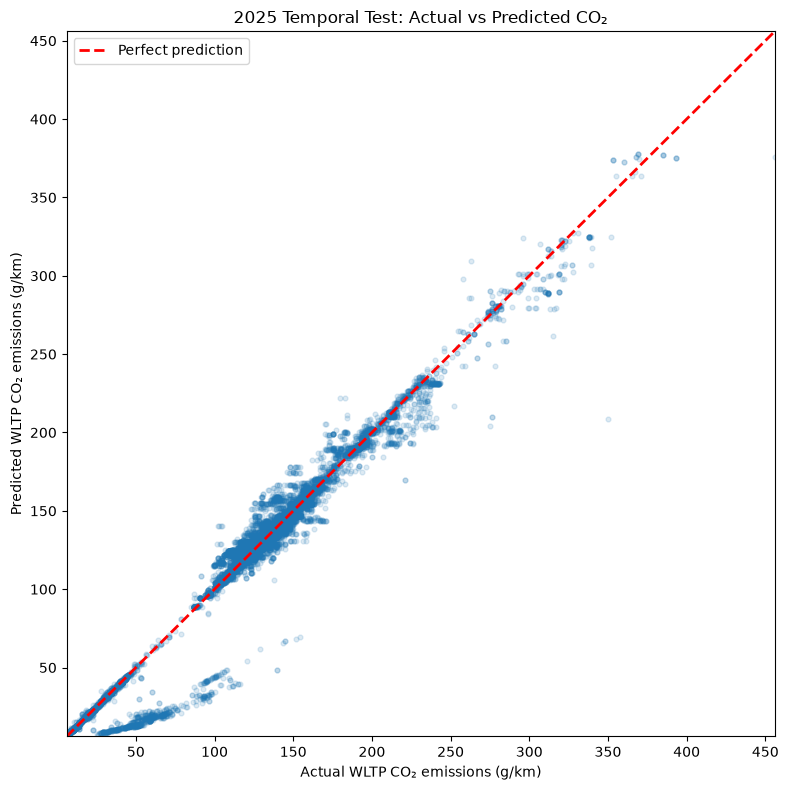

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plot_sample_size = min(20_000, len(y_test))

rng = np.random.default_rng(42)
sample_positions = rng.choice(
    len(y_test),
    size=plot_sample_size,
    replace=False,
)

y_test_array = y_test.to_numpy()

sample_actual = y_test_array[sample_positions]
sample_predicted = y_pred_2025[sample_positions]

lower_limit = min(
    sample_actual.min(),
    sample_predicted.min(),
)

upper_limit = max(
    sample_actual.max(),
    sample_predicted.max(),
)

plt.figure(figsize=(8, 8))

plt.scatter(
    sample_actual,
    sample_predicted,
    alpha=0.15,
    s=12,
)

plt.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction",
)

plt.xlim(lower_limit, upper_limit)
plt.ylim(lower_limit, upper_limit)

plt.xlabel("Actual WLTP CO₂ emissions (g/km)")
plt.ylabel("Predicted WLTP CO₂ emissions (g/km)")
plt.title("2025 Temporal Test: Actual vs Predicted CO₂")
plt.legend()

plt.tight_layout()
plt.show()

## Actual vs Predicted CO₂ Emissions

The scatter plot compares the actual and predicted WLTP CO₂ emissions for the 2025 temporal test set. The red dashed line represents perfect predictions, where the predicted value is equal to the actual value.

Most observations are located close to the perfect-prediction line, indicating strong overall agreement between predicted and observed emissions. The model follows the general upward trend across increasing CO₂ values and performs particularly well through the central portion of the target distribution.

However, the plot reveals several structured error patterns. In the low-emission range, approximately **20–100 g/km**, a distinct secondary group of predictions appears substantially below the perfect-prediction line. This indicates systematic **underprediction** for some low-emission vehicles, potentially due to differences between plug-in hybrid and conventional powertrain configurations.

The model also shows some underprediction for a small number of high-emission vehicles, particularly in the upper tail of the distribution. These errors may be associated with rare high-performance or heavy vehicle configurations that are less represented in the training data.

Overall, the plot confirms that the model captures the main relationship between vehicle specifications and WLTP CO₂ emissions. Nevertheless, the remaining structured errors show that overall performance metrics should be complemented with seen-versus-unseen configuration analysis and subgroup-level error analysis.

## Residual vs. Actual plot

```text
residual=actual CO2−predicted CO2
```
- Positive residual → The model underestimated CO2 levels.
- Negative residual → The model overestimated CO2 levels.

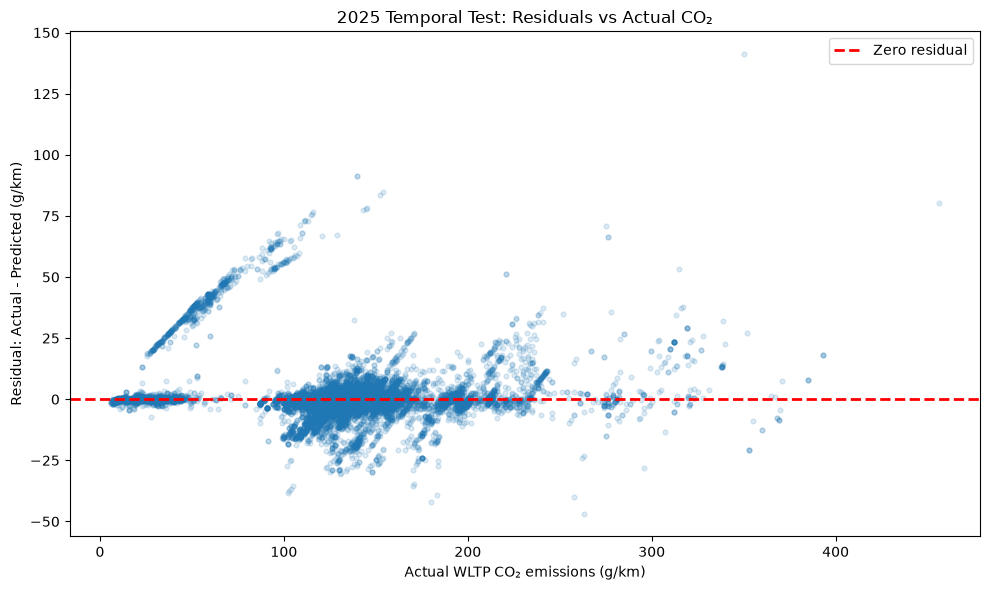

In [26]:
import matplotlib.pyplot as plt
import numpy as np

plot_sample_size = min(20_000, len(y_test))

rng = np.random.default_rng(42)
sample_positions = rng.choice(
    len(y_test),
    size=plot_sample_size,
    replace=False,
)

y_test_array = y_test.to_numpy()
residuals = y_test_array - y_pred_2025

sample_actual = y_test_array[sample_positions]
sample_residuals = residuals[sample_positions]

plt.figure(figsize=(10, 6))

plt.scatter(
    sample_actual,
    sample_residuals,
    alpha=0.15,
    s=12,
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero residual",
)

plt.xlabel("Actual WLTP CO₂ emissions (g/km)")
plt.ylabel("Residual: Actual - Predicted (g/km)")
plt.title("2025 Temporal Test: Residuals vs Actual CO₂")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
import numpy as np

y_test_array = y_test.to_numpy()
residuals = y_test_array - y_pred_2025

print("Residual definition: actual - predicted")
print("Residual min:", residuals.min())
print("Residual max:", residuals.max())
print("Residual mean:", residuals.mean())
print("Residual median:", np.median(residuals))

largest_positive_error = np.argmax(residuals)
largest_negative_error = np.argmin(residuals)

print("\nLargest positive residual:")
print("Actual:", y_test_array[largest_positive_error])
print("Predicted:", y_pred_2025[largest_positive_error])
print("Residual:", residuals[largest_positive_error])

print("\nLargest negative residual:")
print("Actual:", y_test_array[largest_negative_error])
print("Predicted:", y_pred_2025[largest_negative_error])
print("Residual:", residuals[largest_negative_error])

assert np.allclose(
    residuals,
    y_test_array - y_pred_2025,
)

Residual definition: actual - predicted
Residual min: -46.75555434124311
Residual max: 141.1191181349199
Residual mean: 1.1253470707936255
Residual median: -0.13240116693857829

Largest positive residual:
Actual: 350.0
Predicted: 208.8808818650801
Residual: 141.1191181349199

Largest negative residual:
Actual: 263.0
Predicted: 309.7555543412431
Residual: -46.75555434124311


## Residual Analysis

Residuals were defined as:

```text
residual = actual CO₂ − predicted CO₂
```

Therefore, positive residuals indicate underprediction, while negative residuals indicate overprediction.

The residual distribution showed limited overall bias:

- Mean residual: **+1.1253 g/km**
- Median residual: **−0.1324 g/km**
- Minimum residual: **−46.7556 g/km**
- Maximum residual: **+141.1191 g/km**

The median residual was close to zero, indicating that the model was broadly well calibrated for a typical 2025 record. The slightly positive mean residual was caused by a small number of large underpredictions.

The largest underprediction occurred for a vehicle with an actual WLTP CO₂ value of **350.0 g/km**. The model predicted **208.8809 g/km**, resulting in a residual of **+141.1191 g/km**.

The largest overprediction occurred for a vehicle with an actual CO₂ value of **263.0 g/km** and a prediction of **309.7556 g/km**, corresponding to a residual of **−46.7556 g/km**.

The residual-versus-actual plot showed that errors were generally concentrated around zero in the central emission range. However, residual spread increased for low-emission and high-emission vehicles. This pattern suggests that the model captures the dominant relationships between vehicle specifications and CO₂ emissions, while rare vehicle configurations and unobserved design factors remain difficult to predict.

## Next, let's clarify where the model struggles in the petrol, diesel, petrol/electric and diesel/electric categories.

In [28]:
evaluation_2025 = pd.DataFrame({
    "actual_co2": y_test.to_numpy(),
    "predicted_co2": y_pred_2025,
    "absolute_error": np.abs(
        y_test.to_numpy() - y_pred_2025
    ),
    "residual": y_test.to_numpy() - y_pred_2025,
    "Ft_diesel": X_test_final["Ft_diesel"].to_numpy(),
    "Ft_petrol": X_test_final["Ft_petrol"].to_numpy(),
    "Ft_petrol/electric": X_test_final["Ft_petrol/electric"].to_numpy(),
    "Ft_diesel/electric": X_test_final["Ft_diesel/electric"].to_numpy(),
    "Fm_H": X_test_final["Fm_H"].to_numpy(),
    "Fm_M": X_test_final["Fm_M"].to_numpy(),
    "Fm_P": X_test_final["Fm_P"].to_numpy(),
})

evaluation_2025["fuel_type"] = np.select(
    [
        evaluation_2025["Ft_diesel"].eq(1),
        evaluation_2025["Ft_petrol"].eq(1),
        evaluation_2025["Ft_petrol/electric"].eq(1),
        evaluation_2025["Ft_diesel/electric"].eq(1),
    ],
    [
        "diesel",
        "petrol",
        "petrol/electric",
        "diesel/electric",
    ],
    default="unknown",
)

evaluation_2025["fuel_mode"] = np.select(
    [
        evaluation_2025["Fm_H"].eq(1),
        evaluation_2025["Fm_M"].eq(1),
        evaluation_2025["Fm_P"].eq(1),
    ],
    [
        "H",
        "M",
        "P",
    ],
    default="unknown",
)

fuel_error_summary = (
    evaluation_2025
    .groupby(
        ["fuel_type", "fuel_mode"],
        dropna=False,
    )
    .agg(
        records=("actual_co2", "size"),
        actual_mean=("actual_co2", "mean"),
        predicted_mean=("predicted_co2", "mean"),
        mean_residual=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "residual",
            lambda values: np.sqrt(
                np.mean(np.square(values))
            ),
        ),
    )
    .sort_values(
        "mae",
        ascending=False,
    )
    .round(4)
)

display(fuel_error_summary)

,,records,actual_mean,predicted_mean,mean_residual,mae,rmse
fuel_type,fuel_mode,,,,,,
petrol/electric,P,2466,36.5780,27.2893,9.2888,9.8277,20.9308
diesel/electric,P,229,22.6742,13.6320,9.0422,9.3539,18.0501
diesel,H,1276,147.2904,150.1243,-2.8339,6.3760,9.7438
petrol,H,3907,130.6316,131.6282,-0.9967,4.1576,6.3478
diesel,M,3121,157.1871,157.2666,-0.0795,3.8480,6.2369
petrol,M,3736,147.8231,147.9934,-0.1704,3.0551,4.9955


## Error Analysis by Fuel Type and Fuel Mode

To identify which vehicle segments contributed most to the final test error, performance was evaluated separately by fuel type and fuel mode.

| Fuel type | Fuel mode | Records | Actual mean (g/km) | Predicted mean (g/km) | Mean residual (g/km) | MAE (g/km) | RMSE (g/km) |
|---|---|---:|---:|---:|---:|---:|---:|
| petrol/electric | P | 2,466 | 36.5780 | 27.2893 | +9.2888 | 9.8277 | 20.9308 |
| diesel/electric | P | 229 | 22.6742 | 13.6320 | +9.0422 | 9.3539 | 18.0501 |
| diesel | H | 1,276 | 147.2904 | 150.1243 | −2.8339 | 6.3760 | 9.7438 |
| petrol | H | 3,907 | 130.6316 | 131.6282 | −0.9967 | 4.1576 | 6.3478 |
| diesel | M | 3,121 | 157.1871 | 157.2666 | −0.0795 | 3.8480 | 6.2369 |
| petrol | M | 3,736 | 147.8231 | 147.9934 | −0.1704 | 3.0551 | 4.9955 |

Residuals were defined as:

```text
residual = actual CO₂ − predicted CO₂
```

Therefore, positive residuals represent underprediction, while negative residuals represent overprediction.

The largest errors occurred for petrol/electric plug-in hybrid vehicles (`Ft = petrol/electric`, `Fm = P`). This group had an MAE of **9.8277 g/km** and an RMSE of **20.9308 g/km**, substantially higher than the conventional fuel-mode groups.

The mean residual for petrol/electric PHEV vehicles was **+9.2888 g/km**. On average, the model predicted **27.2893 g/km**, while the actual mean was **36.5780 g/km**. This indicates systematic underprediction in this segment.

The diesel/electric plug-in hybrid group (`Ft = diesel/electric`, `Fm = P`) also showed substantial underprediction. It had a mean residual of **+9.0422 g/km**, an MAE of **9.3539 g/km**, and an RMSE of **18.0501 g/km**. However, this group contained only **229 records**, so its results should be interpreted cautiously.

The conventional petrol and diesel groups were substantially better calibrated. Petrol mono-fuel vehicles achieved an RMSE of **4.9955 g/km**, while diesel mono-fuel vehicles achieved an RMSE of **6.2369 g/km**. Their mean residuals were close to zero, at **−0.1704 g/km** and **−0.0795 g/km**, respectively.

Hybrid vehicles also performed reasonably well, although diesel hybrids had a higher RMSE of **9.7438 g/km** than petrol hybrids, which achieved an RMSE of **6.3478 g/km**. Both groups showed only limited average bias, with mean residuals of **−2.8339 g/km** and **−0.9967 g/km**, respectively.

## Analysis of the Largest Prediction Errors

To understand the remaining limitations of the final model, the 20 records with the largest absolute prediction errors in the held-out 2025 temporal test set were examined.

For each record, the analysis includes the vehicle description, fuel type, fuel mode, key technical specifications, actual CO2 emissions, predicted CO2 emissions, residual, absolute error, and whether the core technical configuration had previously appeared in the 2024 training data.

This analysis helps identify whether the largest errors are associated with previously unseen configurations, rare vehicle types, plug-in hybrid vehicles, high-emission outliers, or technical characteristics that are not represented in the final leakage-free feature set.

In [29]:
error_analysis_2025 = X_test.reset_index(drop=True).copy()

error_analysis_2025["actual_co2_g_km"] = y_test.to_numpy()
error_analysis_2025["predicted_co2_g_km"] = y_pred_2025
error_analysis_2025["residual_g_km"] = (
    error_analysis_2025["actual_co2_g_km"]
    - error_analysis_2025["predicted_co2_g_km"]
)
error_analysis_2025["absolute_error_g_km"] = (
    error_analysis_2025["residual_g_km"].abs()
)
error_analysis_2025["configuration_status"] = np.where(
    seen_mask,
    "seen",
    "unseen",
)

inspection_columns = [
    "Vehicle",
    "Mk",
    "Cn",
    "Ft",
    "Fm",
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Electric range (km)",
    "IT",
    "actual_co2_g_km",
    "predicted_co2_g_km",
    "residual_g_km",
    "absolute_error_g_km",
    "configuration_status",
]

inspection_columns = [
    column
    for column in inspection_columns
    if column in error_analysis_2025.columns
]

top_20_errors = (
    error_analysis_2025[
        inspection_columns
    ]
    .sort_values(
        "absolute_error_g_km",
        ascending=False,
    )
    .head(20)
    .round({
        "m (kg)": 1,
        "ec (cm3)": 1,
        "ep (KW)": 1,
        "Electric range (km)": 1,
        "actual_co2_g_km": 2,
        "predicted_co2_g_km": 2,
        "residual_g_km": 2,
        "absolute_error_g_km": 2,
    })
)

display(top_20_errors)

,Ft,Fm,m (kg),ec (cm3),ep (KW),Electric range (km),actual_co2_g_km,predicted_co2_g_km,residual_g_km,absolute_error_g_km,configuration_status
5627,petrol/electric,P,1985.0000,6498.0000,607.0000,13.0000,350.0000,208.8800,141.1200,141.1200,unseen
5634,petrol/electric,P,2580.0000,3996.0000,456.0000,66.0000,140.0000,48.4700,91.5300,91.5300,unseen
5635,petrol/electric,P,2580.0000,3996.0000,456.0000,66.0000,140.0000,48.4700,91.5300,91.5300,unseen
5751,petrol/electric,P,2693.0000,1997.0000,165.0000,44.0000,154.0000,69.2200,84.7800,84.7800,seen
5753,petrol/electric,P,2711.0000,1997.0000,165.0000,45.0000,152.0000,68.4200,83.5800,83.5800,seen
6275,petrol,M,2866.0000,3982.0000,430.0000,0.0000,456.0000,375.8100,80.1900,80.1900,unseen
5752,petrol/electric,P,2693.0000,1997.0000,165.0000,46.0000,145.0600,66.8500,78.2100,78.2100,seen
5754,petrol/electric,P,2711.0000,1997.0000,165.0000,46.0000,144.5000,66.8500,77.6500,77.6500,seen
5750,petrol/electric,P,2693.0000,1997.0000,165.0000,46.6000,143.2900,65.8200,77.4700,77.4700,seen
10348,petrol/electric,P,2670.0000,3996.0000,441.0000,73.8000,116.0000,39.5900,76.4100,76.4100,seen


## Analysis of the Largest Prediction Errors

The 20 records with the largest absolute errors in the 2025 temporal test set were examined to identify systematic model limitations.

The largest errors were not randomly distributed. Most of the highly erroneous records belonged to petrol/electric plug-in hybrid vehicles (`Ft = petrol/electric`, `Fm = P`), particularly high-performance and heavy vehicles.

The largest error occurred for an unseen configuration:

| Feature | Value |
|---|---:|
| Fuel type / mode | petrol/electric / P |
| Mass | 1,985 kg |
| Engine capacity | 6,498 cm³ |
| Engine power | 607 kW |
| Electric range | 13 km |
| Actual CO₂ emissions | 350.0 g/km |
| Predicted CO₂ emissions | 208.88 g/km |
| Absolute error | 141.12 g/km |
| Core configuration status | Unseen |

Although the model captured that this vehicle had an exceptionally large engine and very high power, it substantially underpredicted its emissions. This suggests that the model can overgeneralise the low-emission signal associated with PHEV vehicles, especially for rare, high-performance PHEV configurations with very short electric range.

Several other large errors also involved petrol/electric PHEVs with powerful engines, high vehicle mass, and relatively short electric ranges. In these cases, the model predicted substantially lower CO₂ values than the reported WLTP values. This pattern is consistent with the earlier finding that PHEV vehicles were systematically underpredicted.

A further large error occurred for a petrol mono-fuel vehicle with a 3,982 cm³ engine, 430 kW power output, and an actual CO₂ value of 456.0 g/km. The model predicted 375.81 g/km, producing an absolute error of 80.19 g/km. This record also belonged to an unseen core configuration, indicating that extreme or rarely observed vehicle specifications remain particularly challenging.

Overall, the largest errors were concentrated in unusual or extreme vehicle configurations, especially high-performance PHEVs. These cases suggest that additional specification details—such as drivetrain configuration, battery capacity, vehicle category, or more granular powertrain information—could help the model distinguish efficient PHEVs from high-performance PHEVs with limited electric driving capability.

## Distribution of Absolute Prediction Errors

Overall regression metrics such as MAE and RMSE summarise model performance with a single value, but they do not show how errors are distributed across individual records.

To better understand the practical accuracy of the final model, the distribution of absolute prediction errors was analysed on the held-out 2025 temporal test set.

This analysis includes:

- A histogram of absolute errors, showing how frequently different error magnitudes occur.
- Error percentiles, showing the prediction error threshold below which a given proportion of records falls.

Unlike signed residuals, absolute errors do not distinguish between overprediction and underprediction. Instead, they measure the magnitude of the prediction error in g/km.

This analysis helps distinguish the typical prediction quality for the majority of vehicles from the relatively small number of rare, high-error vehicle configurations that disproportionately affect RMSE.

,Percentile,Absolute error (g/km)
0,50th percentile (Median),1.9700
1,75th percentile,4.6000
2,90th percentile,12.2200
3,95th percentile,22.8700
4,99th percentile,48.9100
5,Maximum,141.1200


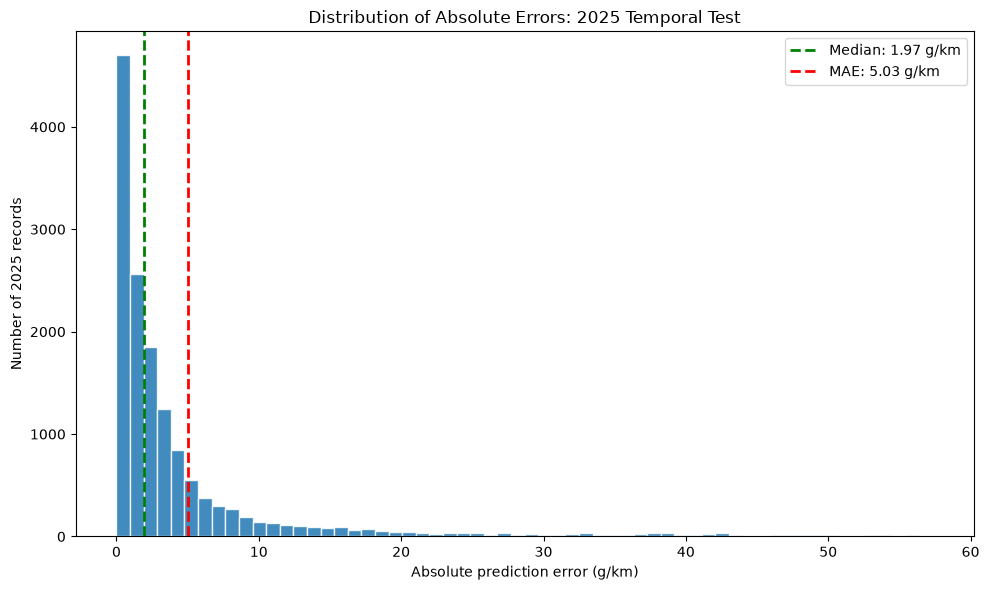

Records with absolute error ≤ 5 g/km: 76.89%
Records with absolute error ≤ 10 g/km: 87.93%
Records with absolute error ≤ 20 g/km: 94.27%


In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

absolute_errors = np.abs(
    y_test.to_numpy() - y_pred_2025
)

error_percentiles = pd.DataFrame({
    "Percentile": [
        "50th percentile (Median)",
        "75th percentile",
        "90th percentile",
        "95th percentile",
        "99th percentile",
        "Maximum",
    ],
    "Absolute error (g/km)": [
        np.percentile(absolute_errors, 50),
        np.percentile(absolute_errors, 75),
        np.percentile(absolute_errors, 90),
        np.percentile(absolute_errors, 95),
        np.percentile(absolute_errors, 99),
        absolute_errors.max(),
    ],
})

display(error_percentiles.round(2))

plot_upper_limit = np.percentile(
    absolute_errors,
    99.5,
)

plt.figure(figsize=(10, 6))

plt.hist(
    absolute_errors,
    bins=60,
    range=(0, plot_upper_limit),
    edgecolor="white",
    alpha=0.85,
)

plt.axvline(
    np.median(absolute_errors),
    color="green",
    linestyle="--",
    linewidth=2,
    label=(
        f"Median: "
        f"{np.median(absolute_errors):.2f} g/km"
    ),
)

plt.axvline(
    np.mean(absolute_errors),
    color="red",
    linestyle="--",
    linewidth=2,
    label=(
        f"MAE: "
        f"{np.mean(absolute_errors):.2f} g/km"
    ),
)

plt.xlabel("Absolute prediction error (g/km)")
plt.ylabel("Number of 2025 records")
plt.title("Distribution of Absolute Errors: 2025 Temporal Test")
plt.legend()

plt.tight_layout()
plt.show()

print(
    "Records with absolute error ≤ 5 g/km:",
    f"{(absolute_errors <= 5).mean() * 100:.2f}%"
)

print(
    "Records with absolute error ≤ 10 g/km:",
    f"{(absolute_errors <= 10).mean() * 100:.2f}%"
)

print(
    "Records with absolute error ≤ 20 g/km:",
    f"{(absolute_errors <= 20).mean() * 100:.2f}%"
)

## Distribution of Absolute Prediction Errors

The distribution of absolute prediction errors was analysed on the held-out 2025 temporal test set.

The error distribution was strongly right-skewed. Most predictions were close to the observed WLTP CO₂ values, while a relatively small number of records produced substantially larger errors.

| Percentile | Absolute error (g/km) |
|---|---:|
| 50th percentile (Median) | 1.9700 |
| 75th percentile | 4.6000 |
| 90th percentile | 12.2200 |
| 95th percentile | 22.8700 |
| 99th percentile | 48.9100 |
| Maximum | 141.1200 |

The model achieved an absolute error of **5 g/km or less for 76.89%** of the 2025 records. For **87.93%** of the records, the absolute error was **10 g/km or less**, and for **94.27%** of the records, it was **20 g/km or less**.

The median absolute error of **1.97 g/km** indicates that the typical prediction was close to the actual value. However, the difference between the median error and the overall MAE of **5.0343 g/km** shows that a smaller number of large errors had a substantial effect on the average error.

The maximum absolute error was **141.12 g/km** and occurred in a rare, high-performance plug-in hybrid configuration. Therefore, the RMSE of **10.5761 g/km** is influenced disproportionately by a small high-error tail, while the majority of predictions remain relatively accurate.

## Error Analysis for Seen/Unseen Vs. Fuel Type/Fuel Mode

The final 2025 test results were analysed jointly by configuration novelty and powertrain segment.

A record was labelled as **seen** when its core technical configuration — defined by vehicle mass, engine capacity, engine power, fuel type, and fuel mode — had already occurred in the combined 2024 training data. Otherwise, it was labelled as **unseen**.

This analysis determines whether prediction errors are primarily driven by new technical configurations, by specific fuel and powertrain groups, or by the combination of both factors.

In [31]:
evaluation_2025["configuration_status"] = np.where(
    seen_mask,
    "seen",
    "unseen",
)

novelty_powertrain_summary = (
    evaluation_2025
    .groupby(
        [
            "configuration_status",
            "fuel_type",
            "fuel_mode",
        ],
        dropna=False,
    )
    .agg(
        records=("actual_co2", "size"),
        actual_mean=("actual_co2", "mean"),
        predicted_mean=("predicted_co2", "mean"),
        mean_residual=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "residual",
            lambda values: np.sqrt(
                np.mean(
                    np.square(values)
                )
            ),
        ),
        median_absolute_error=(
            "absolute_error",
            "median",
        ),
        pct_error_over_20=(
            "absolute_error",
            lambda values: (
                values.gt(20).mean() * 100
            ),
        ),
    )
    .sort_values(
        "rmse",
        ascending=False,
    )
    .round(4)
)

display(novelty_powertrain_summary)

records  actual_mean  \
configuration_status fuel_type       fuel_mode                         
unseen               petrol/electric P              404      44.8005   
                     diesel/electric P               22      37.9365   
seen                 petrol/electric P             2062      34.9670   
                     diesel/electric P              207      21.0521   
unseen               diesel          H              240     146.5259   
                                     M              496     175.8559   
                     petrol          M              424     164.8132   
                                     H              812     136.8319   
seen                 diesel          H             1036     147.4675   
                     petrol          H             3095     129.0048   
                     diesel          M             2625     153.6596   
                     petrol          M             3312     145.6480   

                                                predicted_mean  mean_residual  \
configuration_status fuel_type       fuel_mode                                  
unseen               petrol/electric P                 19.7275        25.0731   
                     diesel/electric P                 17.0100        20.9265   
seen                 petrol/electric P                 28.7708         6.1962   
                     diesel/electric P                 13.2730         7.7791   
unseen               diesel          H                150.8798        -4.3540   
                                     M                175.4246         0.4313   
                     petrol          M                163.4730         1.3402   
                                     H                138.6709        -1.8390   
seen                 diesel          H                149.9493        -2.4818   
                     petrol          H                129.7805        -0.7757   
                     diesel          M                153.8356        -0.1760   
                     petrol          M                146.0118        -0.3638   

                                                   mae    rmse  \
configuration_status fuel_type       fuel_mode                   
unseen               petrol/electric P         25.5461 33.5587   
                     diesel/electric P         21.1726 30.7355   
seen                 petrol/electric P          6.7481 17.4150   
                     diesel/electric P          8.0978 16.1256   
unseen               diesel          H         12.6889 15.5007   
                                     M          8.2570 11.7162   
                     petrol          M          5.8056  9.6622   
                                     H          7.3638  9.6365   
seen                 diesel          H          4.9135  7.8278   
                     petrol          H          3.3165  5.1481   
                     diesel          M          3.0149  4.5068   
                     petrol          M          2.7030  4.0247   

                                                median_absolute_error  \
configuration_status fuel_type       fuel_mode                          
unseen               petrol/electric P                        31.3815   
                     diesel/electric P                         2.2297   
seen                 petrol/electric P                         0.4204   
                     diesel/electric P                         0.3335   
unseen               diesel          H                        12.2451   
                                     M                         4.4938   
                     petrol          M                         3.3216   
                                     H                         6.5544   
seen                 diesel          H                         2.6753   
                     petrol          H                         1.9260   
                     diesel          M                         1.9030   
                     petrol   

### Key Finding: Unseen Petrol/Electric PHEVs Drive Most Large Errors

The joint analysis shows that the high-error tail in the 2025 temporal test set is concentrated overwhelmingly in previously unseen petrol/electric plug-in hybrid (PHEV) configurations.

For unseen petrol/electric vehicles in fuel mode `P`, the model produced an MAE of **25.5461 g/km** and an RMSE of **33.5587 g/km**. These vehicles had an average actual CO₂ value of **44.8005 g/km**, whereas the average prediction was only **19.7275 g/km**. This corresponds to a mean residual of **+25.0731 g/km**, indicating systematic underprediction.

More than half of these unseen PHEV records (**59.9010%**) had an absolute prediction error above 20 g/km. Their median absolute error was also high at **31.3815 g/km**, showing that the issue was not caused only by a small number of extreme outliers.

In contrast, seen petrol/electric PHEV configurations had a much lower MAE of **6.7481 g/km**. However, they still showed a positive mean residual of **+6.1962 g/km** and an RMSE of **17.4150 g/km**, indicating that PHEVs remain more difficult to predict than conventional petrol and diesel vehicles even when their technical configurations have appeared in the training data.

For conventional petrol and diesel vehicles, prediction performance was substantially more stable. Seen configurations generally achieved MAE values between **2.7030 and 4.9135 g/km**, while unseen conventional configurations achieved MAE values between **5.8056 and 12.6889 g/km**. The largest non-PHEV error occurred for unseen diesel hybrid vehicles, with an MAE of **12.6889 g/km** and an RMSE of **15.5007 g/km**.

Therefore, configuration novelty alone does not explain the observed error distribution. The principal challenge is the interaction between configuration novelty and the petrol/electric PHEV segment. New PHEV configurations appear to have CO₂ emission patterns that are not adequately captured by patterns learned from historical data.

# 8. Conclusions

The workflow separates data preparation, feature-set design, model comparison, hyperparameter tuning, and final testing.

The extended specification feature set is the primary choice when electric range and eco-innovation technology indicators are available. The strict design-stage feature set remains useful when predictions must be made before those variables are known.

The final reported test metrics should be interpreted as an estimate of performance on future data from the 2025 FR setting. They should not be used to revise the model-selection decisions retrospectively.